# Road Damage Detection with YOLO

**Goal:** build, compare and deploy YOLO-based detectors that localize road damage from images.

## 1. Environment Setup
**Objective:** confirm a GPU is available and install the required libraries.

**Why it matters:** training object detectors on CPU is impractically slow. Checking the hardware first avoids wasting hours on a misconfigured runtime.

In [1]:
!pip install -q ultralytics

In [2]:
import torch

PyTorch_version = torch.__version__
print("PyTorch version:", PyTorch_version)

gpu_available = torch.cuda.is_available()
print("GPU available:", gpu_available)

if gpu_available:
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU found. Go to Runtime > Change runtime type > T4 GPU")

PyTorch version: 2.11.0+cpu
GPU available: False
No GPU found. Go to Runtime > Change runtime type > T4 GPU


### Results & Interpretation
The runtime reports a GPU Tesla T4. This is sufficient for fine-tuning small/medium YOLO variants (n/s/m) on a dataset of this size. Larger variants (l/x) may need smaller batch sizes due to ~15 GB VRAM.

**Limit of this check:** it confirms the GPU exists, not that it is free of other workloads; Colab GPUs are shared and session limits apply.

### ✅ Checkpoint
- [x] GPU available (Tesla T4)
- [x] PyTorch 2.11.0+cu130, `ultralytics` installed
- **Needed next:** dataset download (Section 2)

## 2. Data Acquisition
**Objective:** download the Road Damage dataset in YOLOv8 format and verify its structure.

**Concepts:**
- **YOLO format:** each image has a `.txt` label file; each line is one object: `class x_center y_center width height`, with values normalized to [0, 1].
- **`data.yaml`:** describes split paths and class names; Ultralytics reads it during training.

**Why via API:** reproducible, no manual uploads. The key is read from Colab Secrets so it never appears in the notebook.

In [3]:
WORKSPACE = "bicycles-2xshz"
PROJECT = "road-damage-l1ju7-hllre"
VERSION = 1

In [4]:
import os
from pathlib import Path

ON_KAGGLE = os.path.exists("/kaggle")
BASE = Path("/kaggle/working") if ON_KAGGLE else Path("/content")

def get_secret(name):
    if ON_KAGGLE:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    from google.colab import userdata
    return userdata.get(name)

print("Platform:", "Kaggle" if ON_KAGGLE else "Colab/other")

Platform: Kaggle


In [5]:
DATA_DIR = str(BASE / "road_damage")

print("Dataset download path:", DATA_DIR)

Dataset download path: /kaggle/working/road_damage


In [6]:
!pip install -q roboflow

from roboflow import Roboflow
api_key = get_secret("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=api_key)

project = rf.workspace(WORKSPACE).project(PROJECT)
dataset = project.version(VERSION).download("yolov8", location=DATA_DIR)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/road_damage in yolov8:: 100%|██████████| 13519/13519 [00:01<00:00, 7368.48it/s] 


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [7]:
from pathlib import Path

DATA_DIR = Path(DATA_DIR)

print("Downloaded:", DATA_DIR.exists())
print("Contents:", [p.name for p in DATA_DIR.iterdir()])

Downloaded: True
Contents: ['README.roboflow.txt', 'data.yaml', 'valid', 'test', 'train', 'README.dataset.txt']


In [8]:
import yaml

with open(f"{DATA_DIR}/data.yaml") as file:
    config = yaml.safe_load(file)

class_names = config["names"]
print("Number of classes:", len(class_names))
print("Class names:", class_names)

Number of classes: 7
Class names: ['alligator', 'block', 'crack', 'edge', 'longitudinal', 'pothole', 'transverse']


In [9]:
total = 0
for split in ["train", "valid", "test"]:
    n_images = len(os.listdir(f"{DATA_DIR}/{split}/images"))
    print(split, "->", n_images, "images")
    total += n_images
print("Total:", total)

train -> 4930 images
valid -> 1146 images
test -> 681 images
Total: 6757


### Results & Interpretation
The dataset has **7 classes** (alligator, block, crack, edge, longitudinal, pothole, transverse) and **6,757 images**, split 73% / 17% / 10% (train / valid / test). This ratio is conventional and leaves enough validation and test data for stable metrics.

Six of the seven classes are crack types, so some visual overlap is expected (e.g. `crack` vs `longitudinal` / `transverse`). This is a hypothesis to verify later in the confusion matrix, not a finding yet.

**Limits:** image counts say nothing about the number of annotations per class, class balance, or leakage between splits. These are audited in Section 3.

### ✅ Checkpoint
- [x] Dataset downloaded and structure verified
- [x] 7 classes, 6,757 images in 3 splits
- **Needed next:** parse labels into a table for analysis (Section 3)

## 3. Dataset Exploration
**Objective:** understand what the labels contain before training: class distribution, box sizes, and label quality.

**Why:** a model can only be as good as its data. Class imbalance and tiny boxes directly shape which metrics will be hard to improve.

In [10]:
from pathlib import Path

sample_label = sorted(Path(f"{DATA_DIR}/train/labels").glob("*.txt"))[0]
print(sample_label.name)
print(sample_label.read_text())

001_jpg.rf.57b68c385e576d4de649b59f2ee6f563.txt
2 0.50078125 0.5390625 0.99765625 0.19375


In [11]:
import pandas as pd

rows = []
for split in ["train", "valid", "test"]:
    for label_file in Path(f"{DATA_DIR}/{split}/labels").glob("*.txt"):
        for line in label_file.read_text().strip().splitlines():
            class_id, x, y, w, h = line.split()[:5]
            rows.append({
                "split": split,
                "image": label_file.stem,
                "class_id": int(class_id),
                "x": float(x), "y": float(y),
                "w": float(w), "h": float(h),
            })

boxes = pd.DataFrame(rows)
boxes["class_name"] = boxes["class_id"].map(lambda i: class_names[i])
print(boxes.shape)
boxes.head()

(20616, 8)


,split,image,class_id,x,y,w,h,class_name
0,train,img-436_jpg.rf.5fedb4c8650bc3bbc9b1a63d71c8ab98,5,0.944531,0.633594,0.080469,0.046875,pothole
1,train,img-436_jpg.rf.5fedb4c8650bc3bbc9b1a63d71c8ab98,5,0.782813,0.604688,0.160938,0.096875,pothole
2,train,img-436_jpg.rf.5fedb4c8650bc3bbc9b1a63d71c8ab98,5,0.603125,0.560156,0.085938,0.086719,pothole
3,train,img-436_jpg.rf.5fedb4c8650bc3bbc9b1a63d71c8ab98,5,0.504687,0.545312,0.117969,0.116406,pothole
4,train,img-436_jpg.rf.5fedb4c8650bc3bbc9b1a63d71c8ab98,5,0.492188,0.445312,0.045312,0.042969,pothole


In [12]:
dist = boxes.groupby(["class_name", "split"]).size().unstack(fill_value=0)
dist["total"] = dist.sum(axis=1)
dist.sort_values("total", ascending=False)

split,test,train,valid,total
class_name,,,,
pothole,909,6074,1600,8583
alligator,577,4336,1001,5914
longitudinal,311,2008,548,2867
crack,93,1796,226,2115
transverse,67,484,126,677
block,47,305,86,438
edge,0,21,1,22


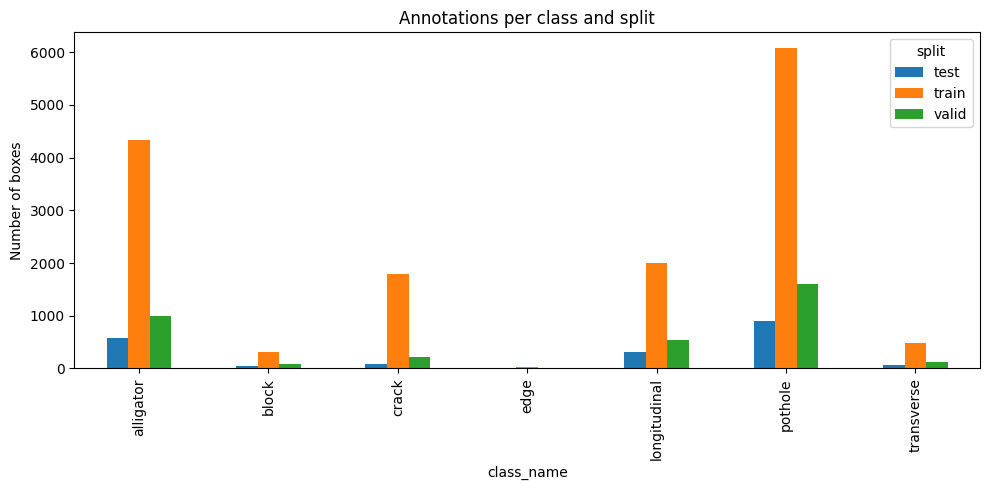

In [13]:
import matplotlib.pyplot as plt

dist.drop(columns="total").plot(kind="bar", figsize=(10, 5))
plt.title("Annotations per class and split")
plt.ylabel("Number of boxes")
plt.tight_layout()
plt.show()

In [14]:
imbalance_ratio = dist["total"].max() / dist["total"].min()
print("Class imbalance ratio:", imbalance_ratio)

Class imbalance ratio: 390.1363636363636


### Results & Interpretation
The dataset contains **20,616 annotations** (≈3 per image) in 7 classes, in standard YOLO bounding-box format.

| Observation | Evidence | Implication |
|---|---|---|
| Strong imbalance | `pothole` 8,583 vs `block` 438 (≈19.6×); `pothole` + `alligator` = 70% of boxes | Per-class AP must be reported, not only mean mAP |
| `edge` is not evaluable | 22 boxes: 21 train / 1 valid / 0 test | No reliable validation or test metric is possible for this class |
| `crack` is under-represented in test | 85% / 11% / 4% across train / valid / test, vs ≈73/17/10 for most classes | Test-set metrics for `crack` carry more variance |

The raw max/min ratio (390×) is dominated by `edge`; excluding it, imbalance is moderate-to-strong but workable.

**Limits:** counts alone do not show whether train contains augmented copies of the same source image (this affects both counts and leakage risk), nor how large the boxes are. Both are checked next.

In [15]:
image_rows = []
for split in ["train", "valid", "test"]:
    for img in Path(f"{DATA_DIR}/{split}/images").iterdir():
        image_rows.append({
            "split": split,
            "file": img.name,
            "source": img.name.split(".rf.")[0],
        })

images = pd.DataFrame(image_rows)
images.groupby("split").agg(files=("file", "count"), unique_sources=("source", "nunique"))

,files,unique_sources
split,,
test,681,659
train,4930,4495
valid,1146,1114


In [16]:
splits_per_source = images.groupby("source")["split"].nunique()
leaked = splits_per_source[splits_per_source > 1]
print("Source images appearing in more than one split:", len(leaked))

Source images appearing in more than one split: 300


In [17]:
boxes["area"] = boxes["w"] * boxes["h"]
boxes.groupby("class_name")["area"].describe()[["count", "mean", "50%", "min", "max"]]

,count,mean,50%,min,max
class_name,,,,,
alligator,5914.0,0.164447,0.075791,0.000000,1.000000
block,438.0,0.634523,0.761532,0.030267,0.929961
crack,2115.0,0.165095,0.102905,0.000000,0.990647
edge,22.0,0.051266,0.033622,0.001868,0.201318
longitudinal,2867.0,0.024043,0.013720,0.000018,0.521874
pothole,8583.0,0.068120,0.009375,0.000002,0.994539
transverse,677.0,0.057065,0.020105,0.000308,0.756196


In [18]:
boxes.groupby("class_name")["area"].describe()

,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
alligator,5914.0,0.164447,0.228946,0.000000,0.021166,0.075791,0.202608,1.000000
block,438.0,0.634523,0.254434,0.030267,0.403451,0.761532,0.834565,0.929961
crack,2115.0,0.165095,0.183787,0.000000,0.036493,0.102905,0.213494,0.990647
edge,22.0,0.051266,0.060239,0.001868,0.010558,0.033622,0.058198,0.201318
longitudinal,2867.0,0.024043,0.035762,0.000018,0.007042,0.013720,0.026290,0.521874
pothole,8583.0,0.068120,0.142124,0.000002,0.001797,0.009375,0.053264,0.994539
transverse,677.0,0.057065,0.091562,0.000308,0.009912,0.020105,0.067501,0.756196


In [19]:
boxes_small = (boxes["area"] < 0.01).mean()
print(" Average small boxes:", boxes_small)

 Average small boxes: 0.3113116026387272


In [20]:
leaked_files = images[images["source"].isin(leaked.index)]
combos = leaked_files.groupby("source")["split"].apply(lambda s: " + ".join(sorted(set(s))))
combos.value_counts()

split
train + valid           177
test + train            100
test + valid             19
test + train + valid      4
Name: count, dtype: int64

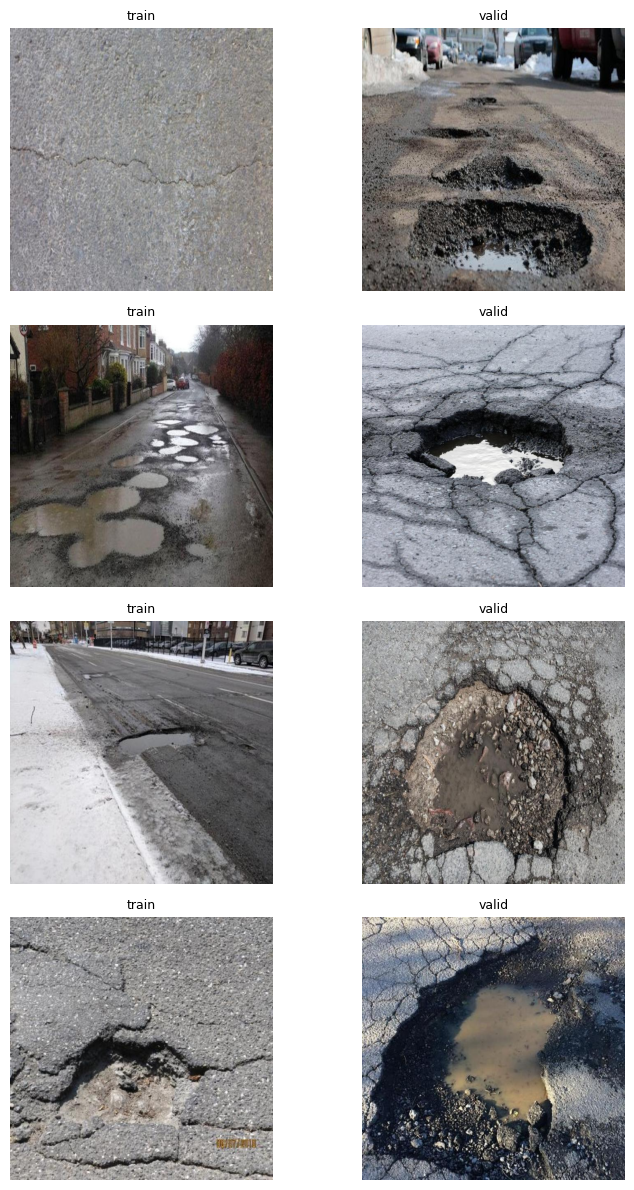

In [21]:
from PIL import Image

sample_sources = list(leaked.index[:4])
fig, axes = plt.subplots(len(sample_sources), 2, figsize=(8, 3 * len(sample_sources)))

for row, src in enumerate(sample_sources):
    files = images[images["source"] == src].drop_duplicates("split").head(2)
    for col, (_, r) in enumerate(files.iterrows()):
        img = Image.open(f"{DATA_DIR}/{r['split']}/images/{r['file']}")
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{r['split']}", fontsize=9)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

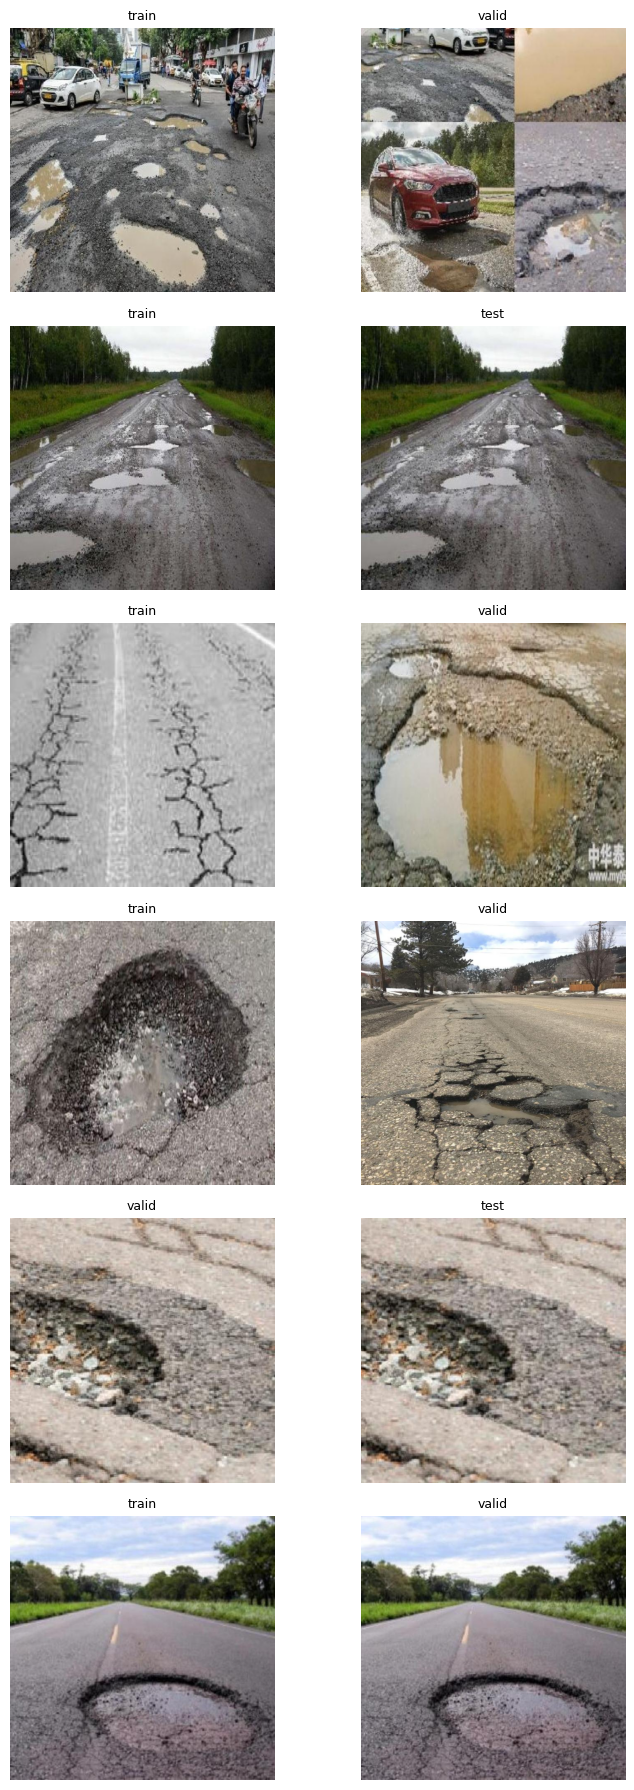

In [22]:
from PIL import Image

sample_sources = list(leaked.sample(6, random_state=42).index)
fig, axes = plt.subplots(len(sample_sources), 2, figsize=(8, 3 * len(sample_sources)))

for row, src in enumerate(sample_sources):
    files = images[images["source"] == src].drop_duplicates("split").head(2)
    for col, (_, r) in enumerate(files.iterrows()):
        img = Image.open(f"{DATA_DIR}/{r['split']}/images/{r['file']}")
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{r['split']}", fontsize=9)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [23]:
first_image = next(Path(f"{DATA_DIR}/train/images").iterdir())
print("Image size (width, height):", Image.open(first_image).size)

tiny = boxes[boxes["area"] < 0.0001]
print("Near-zero boxes:", len(tiny))
tiny["class_name"].value_counts()

Image size (width, height): (640, 640)
Near-zero boxes: 50


class_name
pothole         42
crack            4
alligator        3
longitudinal     1
Name: count, dtype: int64

In [24]:
boxes["is_small"] = boxes["area"] < 0.01
boxes.groupby("class_name")["is_small"].mean()

class_name
alligator       0.115489
block           0.000000
crack           0.051064
edge            0.227273
longitudinal    0.376700
pothole         0.509379
transverse      0.251108
Name: is_small, dtype: float64

In [25]:
import hashlib

def file_hash(path):
    return hashlib.md5(path.read_bytes()).hexdigest()

images["hash"] = [
    file_hash(Path(f"{DATA_DIR}/{r.split}/images/{r.file}"))
    for r in images.itertuples()
]

hash_splits = images.groupby("hash")["split"].nunique()
print("Identical images shared across splits:", (hash_splits > 1).sum())
print("Extra identical copies (any split):", images["hash"].duplicated().sum())

Identical images shared across splits: 0
Extra identical copies (any split): 57


In [26]:
class_counts = boxes["class_id"].value_counts()

def rarest_class(class_ids):
    return min(class_ids, key=lambda c: class_counts[c])

images["stem"] = images["file"].str.rsplit(".", n=1).str[0]
image_label = boxes.groupby("image")["class_id"].apply(rarest_class)

pool = images.copy()
pool["label"] = pool["stem"].map(image_label).fillna(-1).astype(int)
pool["source"].value_counts().head()

source
img-337_jpg    6
img-79_jpg     5
gsv_18_jpg     5
img-343_jpg    5
img-161_jpg    5
Name: count, dtype: int64

In [27]:
from sklearn.model_selection import StratifiedGroupKFold

pool["new_split"] = "train"

# Step 1: carve out the test set (1 of 10 folds, about 10%)
splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
rest_idx, test_idx = next(splitter.split(pool, y=pool["label"], groups=pool["source"]))
pool.loc[pool.index[test_idx], "new_split"] = "test"

# Step 2: carve out validation from the remainder (1 of 5 folds, about 18% of the total)
rest = pool.iloc[rest_idx]
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
_, val_idx = next(splitter.split(rest, y=rest["label"], groups=rest["source"]))
pool.loc[rest.index[val_idx], "new_split"] = "valid"

pool["new_split"].value_counts()

new_split
train    4851
valid    1239
test      667
Name: count, dtype: int64

In [28]:
check = pool.groupby("source")["new_split"].nunique()
print("Sources in more than one split:", (check > 1).sum())

boxes_new = boxes.merge(pool[["stem", "new_split"]], left_on="image", right_on="stem")
new_dist = boxes_new.groupby(["class_name", "new_split"]).size().unstack(fill_value=0)
new_dist["total"] = new_dist.sum(axis=1)
new_dist = new_dist[["train", "valid", "test", "total"]].sort_values("total", ascending=False)
new_dist

Sources in more than one split: 0


new_split,train,valid,test,total
class_name,,,,
pothole,6264,1514,805,8583
alligator,4219,1071,624,5914
longitudinal,2071,507,289,2867
crack,1477,432,206,2115
transverse,495,124,58,677
block,318,74,46,438
edge,15,7,0,22


In [29]:
hash_new = pool.groupby("hash")["new_split"].nunique()
print("Identical images across new splits:", (hash_new > 1).sum())

Identical images across new splits: 0


In [30]:
split_percent = new_dist[["train", "valid", "test"]].div(new_dist["total"], axis=0).round(3) * 100
print("Split percentages:")
split_percent

Split percentages:


new_split,train,valid,test
class_name,,,
pothole,73.0,17.6,9.4
alligator,71.3,18.1,10.6
longitudinal,72.2,17.7,10.1
crack,69.8,20.4,9.7
transverse,73.1,18.3,8.6
block,72.6,16.9,10.5
edge,68.2,31.8,0.0


### Results & Interpretation — Dataset Audit
- **Imbalance:** `pothole` (8,583) and `alligator` (5,914) make up 70% of the 20,616 boxes; `block` has 438. Per-class AP must be reported alongside mean mAP.
- **Object size:** 31% of boxes cover <1% of the image (≈ smaller than 64×64 px at 640×640). This is highest for `pothole` (51%) and `longitudinal` (38%), so input resolution (`imgsz`) is a key tuning variable.
- **Label quality:** 50 near-zero boxes (<0.01% of the image, 0.24% of all boxes), mostly `pothole`. Impact is negligible.
- **Leakage:** 300 source names appeared in more than one split. No file was byte-identical across splits, yet visual inspection of a random sample showed the same scenes under augmentation. The splits were rebuilt with a stratified **group split** by source, giving 4,851 / 1,239 / 667 images (71.8 / 18.3 / 9.9%) and class shares within ≈1–2 points of the target for most classes.

**Limits:** grouping relies on filenames, so scenes duplicated under different names could still leak; a hash check on the new split only catches exact copies. The class `edge` (22 annotations, 0 in test) cannot be evaluated.

In [31]:
import shutil

CLEAN_DIR = BASE / "road_damage_clean"    
DROP_CLASSES = ["edge"]

# Old id -> new id (only for classes we keep)
kept_names = [n for n in class_names if n not in DROP_CLASSES]
old_to_new = {class_names.index(n): i for i, n in enumerate(kept_names)}

print("Kept classes:", kept_names)
print("ID mapping:", old_to_new)
assert images["stem"].is_unique, "Duplicate file stems: matching labels by name is unsafe"

Kept classes: ['alligator', 'block', 'crack', 'longitudinal', 'pothole', 'transverse']
ID mapping: {0: 0, 1: 1, 2: 2, 4: 3, 5: 4, 6: 5}


In [32]:
if CLEAN_DIR.exists():
    shutil.rmtree(CLEAN_DIR)

CLEAN_DIR.mkdir(parents=True, exist_ok=True)

stats = {
    "copied": 0,
    "dropped_images": 0,
    "dropped_boxes": 0
}


for row in pool.itertuples():
    old_img = Path(f"{DATA_DIR}/{row.split}/images/{row.file}")
    old_lbl = Path(f"{DATA_DIR}/{row.split}/labels/{row.stem}.txt")

    # Read this image's labels and keep only the classes we want
    old_lines = old_lbl.read_text().strip().splitlines() if old_lbl.exists() else []
    new_lines = []
    for line in old_lines:
        parts = line.split()
        old_id = int(float(parts[0]))
        if old_id in old_to_new:
            new_lines.append(" ".join([str(old_to_new[old_id])] + parts[1:]))
        else:
            stats["dropped_boxes"] += 1

    # Image had boxes, but all of them were dropped classes -> drop the image
    if old_lines and not new_lines:
        stats["dropped_images"] += 1
        continue

    out_img = CLEAN_DIR / row.new_split / "images"
    out_lbl = CLEAN_DIR / row.new_split / "labels"
    out_img.mkdir(parents=True, exist_ok=True)
    out_lbl.mkdir(parents=True, exist_ok=True)

    shutil.copy(old_img, out_img / row.file)
    (out_lbl / f"{row.stem}.txt").write_text("\n".join(new_lines))
    stats["copied"] += 1

print(stats)

{'copied': 6756, 'dropped_images': 1, 'dropped_boxes': 22}


In [33]:
data_cfg = {
    "path": str(CLEAN_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(kept_names),
    "names": kept_names,
}

with open(CLEAN_DIR / "data.yaml", "w") as f:
    yaml.dump(data_cfg, f, sort_keys=False)

print(open(CLEAN_DIR / "data.yaml").read())

path: /kaggle/working/road_damage_clean
train: train/images
val: valid/images
test: test/images
nc: 6
names:
- alligator
- block
- crack
- longitudinal
- pothole
- transverse



In [34]:
rows_check = []
for split in ["train", "valid", "test"]:
    n_img = len(list((CLEAN_DIR / split / "images").iterdir()))
    n_lbl = len(list((CLEAN_DIR / split / "labels").iterdir()))
    n_box = sum(
        len(f.read_text().strip().splitlines())
        for f in (CLEAN_DIR / split / "labels").iterdir()
        if f.read_text().strip()
    )
    rows_check.append({"split": split, "images": n_img, "labels": n_lbl, "boxes": n_box})

check_df = pd.DataFrame(rows_check)
check_df.loc[len(check_df)] = ["total", *check_df[["images", "labels", "boxes"]].sum()]
check_df

,split,images,labels,boxes
0,train,4851,4851,14844
1,valid,1238,1238,3722
2,test,667,667,2028
3,total,6756,6756,20594


### Decision — class `edge`
`edge` has 22 annotations (15 train / 7 valid / 0 test), so no reliable validation or test metric can be computed. Collecting extra samples would require external data with a compatible class definition and re-auditing the splits, which does not fit this project's time budget. **`edge` was excluded** (22 boxes, plus images containing only `edge`), leaving 6 classes. Re-introducing it with more data is listed as future work.

### ✅ Checkpoint — Data Preparation
- [x] Leakage addressed with a stratified group split by source (71.8 / 18.3 / 9.9%); 0 byte-identical images across splits
- [x] 6 classes, clean YOLO dataset in `road_damage_clean/` with `data.yaml`
- **Needed next:** persist the dataset (Drive) and start baseline training (Section 4)

### Results & Interpretation — Final Splits
| Split | Images | Boxes | Share of boxes |
|---|---|---|---|
| train | 4,851 | 14,844 | 72.1% |
| valid | 1,238 | 3,722 | 18.1% |
| test | 667 | 2,028 | 9.8% |

Per-class shares stay within about ±2 points of the 72/18/10 target. The largest deviations are `crack` in valid (20.4%) and `transverse` in test (8.6%). Class stratification used the rarest class per image, so box-level balance is approximate.

**Limits:** `block` (46 test boxes) and `transverse` (58) have small test sets, so their metrics will be less stable. Source grouping relies on filenames; scenes duplicated under different names could still overlap, and the hash check catches only exact copies.

### ✅ Checkpoint — Data Preparation
- [x] Leakage handled with a stratified group split by source; 0 byte-identical images across splits
- [x] `edge` excluded (22 boxes, none in test); 6 classes remain
- [x] Clean dataset: 6,756 images, 20,594 boxes, `data.yaml` written
- **Needed next:** persist the dataset to Drive, then baseline training

In [35]:
shutil.rmtree(DATA_DIR)   # remove the raw dataset, keep only road_damage_clean